In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


In [14]:

def load_data(file_path):
    """
    Load the dataset from a CSV file.

    Parameters:
    file_path (str): The path to the CSV file.

    Returns:
    pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    try:
        df = pd.read_csv(file_path)
        print("Dataset loaded successfully!")
        return df
    except FileNotFoundError:
        print(f"File not found: {file_path}")
        return None

In [15]:
#load the customer churn dataset into a DataFrame
df = load_data("customer_churn_dataset.csv")

Dataset loaded successfully!


In [16]:
#1. check the dataset shape, column names, and data types
print("dataset shape:", df.shape)
print("\ncolumn names:")
print(df.columns.tolist())

print("\ndataset info:")
print(df.info())

print("\nmissing values:")
print(df.isnull().sum())

print("\nduplicate rows:")
print(df.duplicated().sum())


dataset shape: (64374, 12)

column names:
['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']

dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   CustomerID         64374 non-null  int64
 1   Age                64374 non-null  int64
 2   Gender             64374 non-null  str  
 3   Tenure             64374 non-null  int64
 4   Usage Frequency    64374 non-null  int64
 5   Support Calls      64374 non-null  int64
 6   Payment Delay      64374 non-null  int64
 7   Subscription Type  64374 non-null  str  
 8   Contract Length    64374 non-null  str  
 9   Total Spend        64374 non-null  int64
 10  Last Interaction   64374 non-null  int64
 11  Churn              64374 non-null  int64
dtypes: int64(9), str(

In [17]:
#2. check churn distribution
print("\nchurn distribution:")
print(df['Churn'].value_counts())

#3. check gender distribution
print("\ngender distribution:")
print(df['Gender'].value_counts())

#4. check subscription type distribution
print("\nsubscription type distribution:")
print(df['Subscription Type'].value_counts())

#5. check contact length value distribution
print("\ncontact length distribution:")
print(df['Contract Length'].value_counts())

#6. check numerical columns summary
print("\nnumerical columns summary:")
print(df.describe())





churn distribution:
Churn
0    33881
1    30493
Name: count, dtype: int64

gender distribution:
Gender
Female    34353
Male      30021
Name: count, dtype: int64

subscription type distribution:
Subscription Type
Standard    21502
Basic       21451
Premium     21421
Name: count, dtype: int64

contact length distribution:
Contract Length
Monthly      22130
Annual       21410
Quarterly    20834
Name: count, dtype: int64

numerical columns summary:
         CustomerID           Age        Tenure  Usage Frequency  \
count  64374.000000  64374.000000  64374.000000     64374.000000   
mean   32187.500000     41.970982     31.994827        15.080234   
std    18583.317451     13.924911     17.098234         8.816470   
min        1.000000     18.000000      1.000000         1.000000   
25%    16094.250000     30.000000     18.000000         7.000000   
50%    32187.500000     42.000000     33.000000        15.000000   
75%    48280.750000     54.000000     47.000000        23.000000   
max   

In [18]:
#7. check gender vs churn distribution
print("Gender vs Churn")
print(pd.crosstab(df['Gender'], df['Churn']))

#8. check subscription type vs churn distribution
print("\nSubscription Type vs Churn")
print(pd.crosstab(df['Subscription Type'], df['Churn']))

#9. check contract length vs churn distribution
print("\nContract Length vs Churn")
print(pd.crosstab(df['Contract Length'], df['Churn']))



Gender vs Churn
Churn       0      1
Gender              
Female  15442  18911
Male    18439  11582

Subscription Type vs Churn
Churn                  0      1
Subscription Type              
Basic              11095  10356
Premium            11461   9960
Standard           11325  10177

Contract Length vs Churn
Churn                0      1
Contract Length              
Annual           11515   9895
Monthly          10709  11421
Quarterly        11657   9177


In [19]:
#10. calculate the percentage of churn 0 and 1 for each gender
pd.crosstab(
    df['Gender'],
    df['Churn'],
    normalize="index"
    )*100



Churn,0,1
Gender,,
Female,44.950950,55.049050
Male,61.420339,38.579661


In [20]:
#11. calculate the percentage of churn 0 and 1 for each subscription type
df.groupby("Churn")[[
    "Age",
    "Tenure",
    "Payment Delay",
    "Usage Frequency",
    "Support Calls",
    "Total Spend",
    "Last Interaction",

]].mean()


,Age,Tenure,Payment Delay,Usage Frequency,Support Calls,Total Spend,Last Interaction
Churn,,,,,,,
0,41.132700,28.826481,12.453086,16.042915,4.500753,560.541956,15.521944
1,42.902404,35.515200,22.334897,14.010593,6.400617,519.336143,15.473191


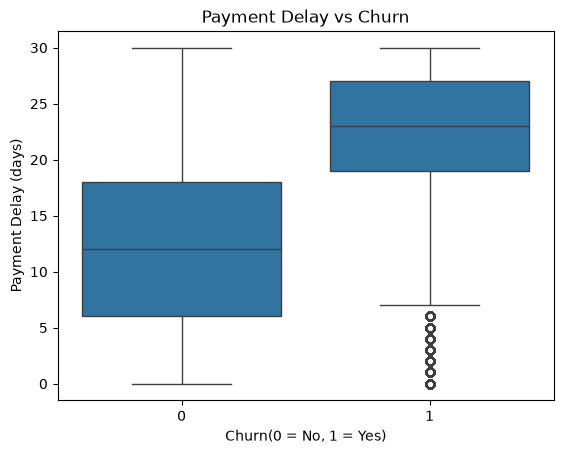

In [21]:
#12. compare payment delay distribution between churned and non-churned customers
sns.boxplot(x="Churn", y="Payment Delay", data=df)

plt.title("Payment Delay vs Churn")
plt.xlabel("Churn(0 = No, 1 = Yes)")
plt.ylabel("Payment Delay (days)")
plt.show()

In [22]:
#13. identify unique categories in categorical features before encoding
print("Gender:", df['Gender'].unique())
print("Subscription Type:", df['Subscription Type'].unique())
print("Contract Length:", df['Contract Length'].unique())

Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Subscription Type: <StringArray>
['Basic', 'Standard', 'Premium']
Length: 3, dtype: str
Contract Length: <StringArray>
['Monthly', 'Annual', 'Quarterly']
Length: 3, dtype: str


In [23]:
#14 identify numerical features before preprocessing
df.select_dtypes(include=[np.number]).columns.tolist()

#15. store numerical columns for preprocessing
numerical_features = df.select_dtypes(include=[np.number]).columns

print("Numerical features:")
print(numerical_features.tolist())


Numerical features:
['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn']


In [24]:
#16. identify categorical features before encoding
categorical_features = df.select_dtypes(include=[object]).columns
print("Categorical features:")
print(categorical_features.tolist())

Categorical features:
['Gender', 'Subscription Type', 'Contract Length']


C:\Users\visha\AppData\Local\Temp\ipykernel_10096\3329184024.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=[object]).columns


In [25]:
#17. separate features(x) and target variable(y)
target_column = "Churn"
x = df.drop(columns=[target_column, "CustomerID"])
y = df[target_column]

print("Features:", x.shape)
print("Target:", y.shape)

print("\nFeatures columns:")
print(x.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


Features: (64374, 10)
Target: (64374,)

Features columns:
['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction']

Target distribution:
Churn
0    33881
1    30493
Name: count, dtype: int64


In [26]:
#18. identify numerical and categorical features
numerical_features = x.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = x.select_dtypes(include=['object']).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical features: ['Gender', 'Subscription Type', 'Contract Length']


C:\Users\visha\AppData\Local\Temp\ipykernel_10096\118276607.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = x.select_dtypes(include=['object']).columns.tolist()


In [27]:
#19. unique values in categorical features
print("Unique values in Gender:", df["Gender"].unique())
print("Unique values in Subscription Type:", df["Subscription Type"].unique())
print("Unique values in Contract Length:", df["Contract Length"].unique())

Unique values in Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Unique values in Subscription Type: <StringArray>
['Basic', 'Standard', 'Premium']
Length: 3, dtype: str
Unique values in Contract Length: <StringArray>
['Monthly', 'Annual', 'Quarterly']
Length: 3, dtype: str


In [28]:
#20. split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


x_train: (51499, 10)
x_test: (12875, 10)
y_train: (51499,)
y_test: (12875,)


In [29]:
#check features data types before preprocessing
print("x_train data types:")
print(x_train.dtypes)

x_train data types:
Age                  int64
Gender                 str
Tenure               int64
Usage Frequency      int64
Support Calls        int64
Payment Delay        int64
Subscription Type      str
Contract Length        str
Total Spend          int64
Last Interaction     int64
dtype: object


In [30]:
numerical_features = x.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = x.select_dtypes(
    include=['object']
).columns.tolist()


C:\Users\visha\AppData\Local\Temp\ipykernel_10096\2122286435.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = x.select_dtypes(


In [31]:
Preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


Logistic_model = Pipeline([
    ("preprocessor", Preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
print(Logistic_model)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Tenure',
                                                   'Usage Frequency',
                                                   'Support Calls',
                                                   'Payment Delay',
                                                   'Total Spend',
                                                   'Last Interaction']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender',
                                                   'Subscription Type',
                                                   'Contract Length'])])),
                ('classifier', LogisticRegression(max_iter=1000))])


In [32]:
Logistic_model.fit(x_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Age','Gender','Tenure',...,'Contract Length','Total Spend', 'Last Interaction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [33]:
#accuracy check
y_pred = Logistic_model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print("LogisticRegression Accuracy", accuracy)

#classification_report
print("classification_report")
print(classification_report(y_test, y_pred))

#confusion matrix
cm=confusion_matrix(y_test,y_pred)
print("confusion matrix")
print(cm)


LogisticRegression Accuracy 0.8270291262135923
classification_report
              precision    recall  f1-score   support

           0       0.84      0.83      0.83      6776
           1       0.81      0.82      0.82      6099

    accuracy                           0.83     12875
   macro avg       0.83      0.83      0.83     12875
weighted avg       0.83      0.83      0.83     12875

confusion matrix
[[5626 1150]
 [1077 5022]]


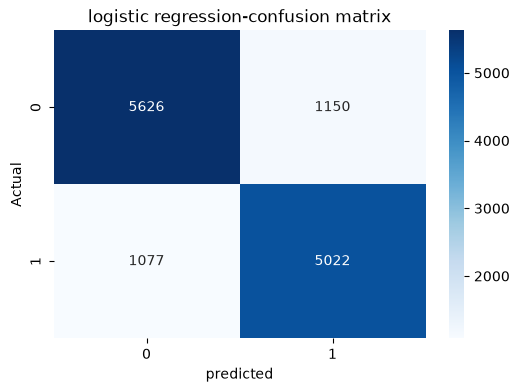

In [34]:
#accuracy check,classification_report,confusion matrix in visual

plt.figure(figsize=(6,4))

sns.heatmap(

    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("logistic regression-confusion matrix")
plt.show()


In [35]:
# Sample Customer Prediction using Logistic Regression

sample_customer = x_test.iloc[[0]]

prediction = Logistic_model.predict(sample_customer)[0]
probability = Logistic_model.predict_proba(sample_customer)[0][1]

print("Churn Prediction:", prediction)
print("Churn Probability:", f"{probability:.2%}")
print("\nCustomer Details:")
print(sample_customer)


Churn Prediction: 0
Churn Probability: 1.56%

Customer Details:
      Age Gender  Tenure  Usage Frequency  Support Calls  Payment Delay  \
7437   26   Male      51               19              6              3   

     Subscription Type Contract Length  Total Spend  Last Interaction  
7437           Premium       Quarterly          761                21  


In [36]:
# Decision Tree Model

decision_tree_model = Pipeline([
    ("preprocessor", Preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

decision_tree_model.fit(x_train, y_train)

y_pred_dt = decision_tree_model.predict(x_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("===== Decision Tree Evaluation =====")
print("Accuracy:", dt_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))



===== Decision Tree Evaluation =====
Accuracy: 0.9991456310679612

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6776
           1       1.00      1.00      1.00      6099

    accuracy                           1.00     12875
   macro avg       1.00      1.00      1.00     12875
weighted avg       1.00      1.00      1.00     12875


Confusion Matrix:
[[6767    9]
 [   2 6097]]


In [37]:
# Random Forest Model

random_forest_model = Pipeline([
    ("preprocessor", Preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(x_train, y_train)

y_pred_rf = random_forest_model.predict(x_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("===== Random Forest Evaluation =====")
print("Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

===== Random Forest Evaluation =====
Accuracy: 0.9985242718446602

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6776
           1       1.00      1.00      1.00      6099

    accuracy                           1.00     12875
   macro avg       1.00      1.00      1.00     12875
weighted avg       1.00      1.00      1.00     12875


Confusion Matrix:
[[6773    3]
 [  16 6083]]


In [55]:
# Final ML + Gemini Prediction Function

import time

def predict_customer_churn(customer_data):

    # 1. ML prediction
    prediction = final_model.predict(customer_data)[0]

    # 2. Churn probability
    probability = final_model.predict_proba(customer_data)[0][1]

    # 3. Prediction status
    if prediction == 1:
        status = "Likely to Churn"
    else:
        status = "Likely to Stay"

    # 4. AI prompt
    ai_prompt = f"""
    Analyze this customer churn prediction.

    ML Prediction: {status}
    Churn Probability: {probability:.2%}

    Give:
    1. A simple explanation of the prediction.
    2. Two practical customer-retention suggestions.

    Do not invent customer information.
    Do not assign low, medium, or high risk unless a threshold is provided.
    """

    # 5. Gemini models
    models_to_try = [
        "gemini-3.8-flash",
        "gemini-3.7-flash"
    ]

    response = None
    last_error = None

    # 6. Try Gemini with retry
    for model in models_to_try:

        for attempt in range(2):

            try:
                response = client.models.generate_content(
                    model=model,
                    contents=ai_prompt
                )

                if response is not None:
                    break

            except Exception as error:
                last_error = error

                if attempt == 0:
                    time.sleep(5)

        if response is not None:
            break

    # 7. AI explanation
    if response is not None:
        ai_explanation = response.text
    else:
        ai_explanation = (
            "Gemini is temporarily unavailable. "
            "The ML prediction was completed successfully."
        )

    # 8. Return result
    return {
        "prediction": status,
        "churn_probability": probability,
        "ai_explanation": ai_explanation
    }

In [39]:
# Cross-Validation Check

from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_dt = cross_val_score(
    decision_tree_model,
    x_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

cv_scores_rf = cross_val_score(
    random_forest_model,
    x_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Decision Tree CV Accuracy:", round(cv_scores_dt.mean(), 4))
print("Random Forest CV Accuracy:", round(cv_scores_rf.mean(), 4))

print("\nNote: Very high accuracy should be checked for possible data leakage or highly predictive features.")


Decision Tree CV Accuracy: 0.9984
Random Forest CV Accuracy: 0.9984

Note: Very high accuracy should be checked for possible data leakage or highly predictive features.


## Final Churn Prediction

For the final demonstration, the Random Forest pipeline is used because it is the selected model for this project workflow. The test-set metrics and cross-validation results above should be considered together when discussing performance.


In [40]:
# Final Model

final_model = random_forest_model

sample_customer = x_test.iloc[[0]]

prediction = final_model.predict(sample_customer)[0]
probability = final_model.predict_proba(sample_customer)[0][1]

print("Final Churn Prediction:", prediction)
print("Churn Probability:", f"{probability:.2%}")


Final Churn Prediction: 0
Churn Probability: 1.00%


In [41]:
# Customer Churn Analysis

churn_predictions = final_model.predict(x_test)
churn_probabilities = final_model.predict_proba(x_test)[:, 1]

print("Customer Churn Analysis")
print("-----------------------")
print("Predictions generated successfully.")
print("Number of customers:", len(churn_predictions))
print("Predicted churn customers:", int(churn_predictions.sum()))
print(
    "Predicted non-churn customers:",
    len(churn_predictions) - int(churn_predictions.sum())
)


Customer Churn Analysis
-----------------------
Predictions generated successfully.
Number of customers: 12875
Predicted churn customers: 6086
Predicted non-churn customers: 6789


In [42]:
# Sample Churn Probabilities

prediction_df = x_test.copy()

prediction_df["Actual_Churn"] = y_test.values
prediction_df["Predicted_Churn"] = churn_predictions
prediction_df["Churn_Probability"] = churn_probabilities

prediction_df.head(10)


,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Actual_Churn,Predicted_Churn,Churn_Probability
7437,26,Male,51,19,6,3,Premium,Quarterly,761,21,0,0,0.01
54961,51,Female,7,4,7,0,Basic,Monthly,612,4,1,1,0.86
33685,52,Male,23,28,1,24,Premium,Annual,937,24,0,0,0.01
20607,48,Male,57,30,10,0,Standard,Monthly,362,22,0,0,0.04
34098,41,Female,45,27,5,9,Basic,Monthly,675,27,0,0,0.01
25054,26,Female,44,6,0,0,Basic,Monthly,226,11,0,0,0.02
21914,20,Male,45,10,0,19,Premium,Annual,606,20,0,0,0.03
42952,29,Female,4,16,5,2,Standard,Quarterly,796,26,0,0,0.01
26694,54,Male,31,27,7,11,Basic,Quarterly,412,28,0,0,0.01
18601,56,Female,28,8,7,6,Standard,Quarterly,542,21,0,0,0.03


In [43]:
# Customer Churn Summary

total_customers = len(y_test)
churn_customers = int(churn_predictions.sum())
non_churn_customers = total_customers - churn_customers

churn_rate = (churn_customers / total_customers) * 100

print("Customer Churn Summary")
print("----------------------")
print("Total Customers:", total_customers)
print("Predicted Churn:", churn_customers)
print("Predicted Non-Churn:", non_churn_customers)
print("Predicted Churn Rate:", round(churn_rate, 2), "%")


Customer Churn Summary
----------------------
Total Customers: 12875
Predicted Churn: 6086
Predicted Non-Churn: 6789
Predicted Churn Rate: 47.27 %


In [44]:
# Create Prompt for AI Explanation

customer_data = sample_customer

prediction = final_model.predict(customer_data)[0]
probability = final_model.predict_proba(customer_data)[0][1]

prompt = f"""
You are a customer churn analysis assistant.

Analyze the following customer:

Customer details:
{customer_data.to_dict(orient="records")[0]}

The machine learning model predicted:
- Churn prediction: {prediction}
- Churn probability: {probability:.2%}

Please provide:
1. A simple explanation of the prediction.
2. Customer characteristics relevant to churn risk, using only the provided data.
3. A practical interpretation of the model probability.
4. Two practical customer-retention suggestions.

Do not invent information that is not present in the customer data.
Do not assign low, medium, or high risk unless a specific threshold is provided.
"""

print(prompt)



You are a customer churn analysis assistant.

Analyze the following customer:

Customer details:
{'Age': 26, 'Gender': 'Male', 'Tenure': 51, 'Usage Frequency': 19, 'Support Calls': 6, 'Payment Delay': 3, 'Subscription Type': 'Premium', 'Contract Length': 'Quarterly', 'Total Spend': 761, 'Last Interaction': 21}

The machine learning model predicted:
- Churn prediction: 0
- Churn probability: 1.00%

Please provide:
1. A simple explanation of the prediction.
2. Customer characteristics relevant to churn risk, using only the provided data.
3. A practical interpretation of the model probability.
4. Two practical customer-retention suggestions.

Do not invent information that is not present in the customer data.
Do not assign low, medium, or high risk unless a specific threshold is provided.



In [45]:
# Gemini API Package

#%pip install -q -U google-genai


In [46]:
# Gemini API Setup

from getpass import getpass
from google import genai

api_key = getpass("Enter your Gemini API key: ").strip()

while not api_key:
	print("The API key cannot be empty.")
	api_key = getpass("Enter your Gemini API key: ").strip()

client = genai.Client(api_key=api_key)

print("Gemini client created successfully.")


Gemini client created successfully.


In [51]:
# Gemini Connection Test

import time

GEMINI_MODEL = "gemini-3.8-flash"
test_prompt = "Explain customer churn in one simple sentence."

test_response = None
last_error = None

for attempt in range(3):
    try:
        test_response = client.models.generate_content(
            model=GEMINI_MODEL,
            contents=test_prompt
        )
        break
    except Exception as error:
        last_error = error
        if attempt < 2:
            time.sleep(2 ** attempt)

if test_response is not None:
    print(test_response.text)
else:
    print("Gemini is currently unavailable.")
    print("Check the API key, model availability, quota, or internet connection.")
    print("Technical details:", last_error)


Customer churn is when existing customers stop doing business with a company or cancel their services.


In [52]:
# Optional: List Available Gemini Models

for model in client.models.list():
    print(model.name)


models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/lyria-3.5
models/gemini-3.1-flash-tts-preview
models/

In [53]:
# Final Customer Churn Prediction + AI Explanation

def predict_customer_churn(customer_data):
    # 1. Make prediction using the trained Random Forest pipeline
    prediction = final_model.predict(customer_data)[0]

    # 2. Get churn probability
    probability = final_model.predict_proba(customer_data)[0][1]

    # 3. Convert prediction into a readable result
    if prediction == 1:
        churn_status = "Likely to Churn"
    else:
        churn_status = "Likely to Stay"

    # 4. Create AI prompt
    ai_prompt = f"""
You are a customer churn analysis assistant.

Customer churn prediction: {churn_status}
Churn probability: {probability:.2%}

Customer details:
{customer_data.to_dict(orient="records")[0]}

Explain this prediction in simple business-friendly language.

Include:
1. Prediction
2. Churn probability
3. Possible reasons based only on the provided customer information
4. Recommended business action

Do not invent customer information.
Do not assign low, medium, or high risk unless a threshold is provided.
"""

    # 5. Ask Gemini for an explanation
    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=ai_prompt
    )

    # 6. Return the complete result
    return {
        "prediction": churn_status,
        "churn_probability": round(probability, 4),
        "ai_explanation": response.text
    }


In [56]:
# Final Customer Churn Result

sample_customer = x_test.iloc[[0]]

result = predict_customer_churn(sample_customer)

print("========== CUSTOMER CHURN RESULT ==========")
print("Prediction:", result["prediction"])
print("Churn Probability:", f"{result['churn_probability']:.2%}")

print("\n========== AI EXPLANATION ==========")
print(result["ai_explanation"])


========== CUSTOMER CHURN RESULT ==========
Prediction: Likely to Stay
Churn Probability: 1.00%

========== AI EXPLANATION ==========
### 1. Explanation of the Prediction
The machine learning model predicts that the customer is **Likely to Stay**. Based on the model's assessment, there is a **1.00% probability** of the customer churning (leaving), which corresponds to a 99.00% likelihood that they will continue their relationship with the business.

---

### 2. Customer-Retention Suggestions
1. **Maintain Proactive Engagement:** Continue delivering consistent value by monitoring service satisfaction, providing reliable customer support, and gathering periodic feedback to ensure their experience remains positive.
2. **Encourage Loyalty and Advocacy:** Introduce loyalty perks, early access to new features, or a referral program to deepen the customer's relationship with the brand and incentivize long-term commitment.
